In [ ]:
import zipfile

!wget https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip

--2026-01-26 06:30:23--  https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 142.250.107.207, 173.194.202.207, 173.194.203.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.250.107.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 168546183 (161M) [application/zip]
Saving to: ‘10_food_classes_10_percent.zip.1’

10_food_classes_10_ 100%[===================>] 160.74M   211MB/s    in 0.8s    

2026-01-26 06:30:24 (211 MB/s) - ‘10_food_classes_10_percent.zip.1’ saved [168546183/168546183]



In [ ]:
with zipfile.ZipFile('/content/10_food_classes_10_percent.zip') as zip_ref:
  zip_ref.extractall()

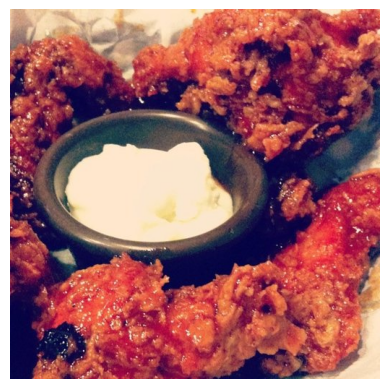

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
img = mpimg.imread('/content/10_food_classes_10_percent/train/chicken_wings/1022742.jpg')
imgplot = plt.imshow(img)
plt.axis(False);

In [ ]:
import os
for (dirpath, dirnames, filenames) in os.walk('/content/10_food_classes_10_percent'):
  print(f'There are {len(dirpath)} directories and {len(filenames)} images in {dirpath}')

There are 35 directories and 0 images in /content/10_food_classes_10_percent
There are 41 directories and 0 images in /content/10_food_classes_10_percent/train
There are 56 directories and 75 images in /content/10_food_classes_10_percent/train/grilled_salmon
There are 47 directories and 75 images in /content/10_food_classes_10_percent/train/pizza
There are 55 directories and 75 images in /content/10_food_classes_10_percent/train/chicken_curry
There are 47 directories and 75 images in /content/10_food_classes_10_percent/train/sushi
There are 52 directories and 75 images in /content/10_food_classes_10_percent/train/fried_rice
There are 51 directories and 75 images in /content/10_food_classes_10_percent/train/hamburger
There are 55 directories and 75 images in /content/10_food_classes_10_percent/train/chicken_wings
There are 51 directories and 75 images in /content/10_food_classes_10_percent/train/ice_cream
There are 47 directories and 75 images in /content/10_food_classes_10_percent/trai

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_dir = "/content/10_food_classes_10_percent/train/"
test_dir = "/content/10_food_classes_10_percent/test/"


train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_data_10_percent = train_datagen.flow_from_directory(directory = train_dir,
                                               target_size=(224,224),
                                               batch_size=32,
                                               class_mode='categorical')
test_data_10_percent = test_datagen.flow_from_directory(directory = test_dir,
                                               target_size=(224,224),
                                               batch_size=32,
                                               class_mode='categorical')

Found 750 images belonging to 10 classes.
Found 2500 images belonging to 10 classes.


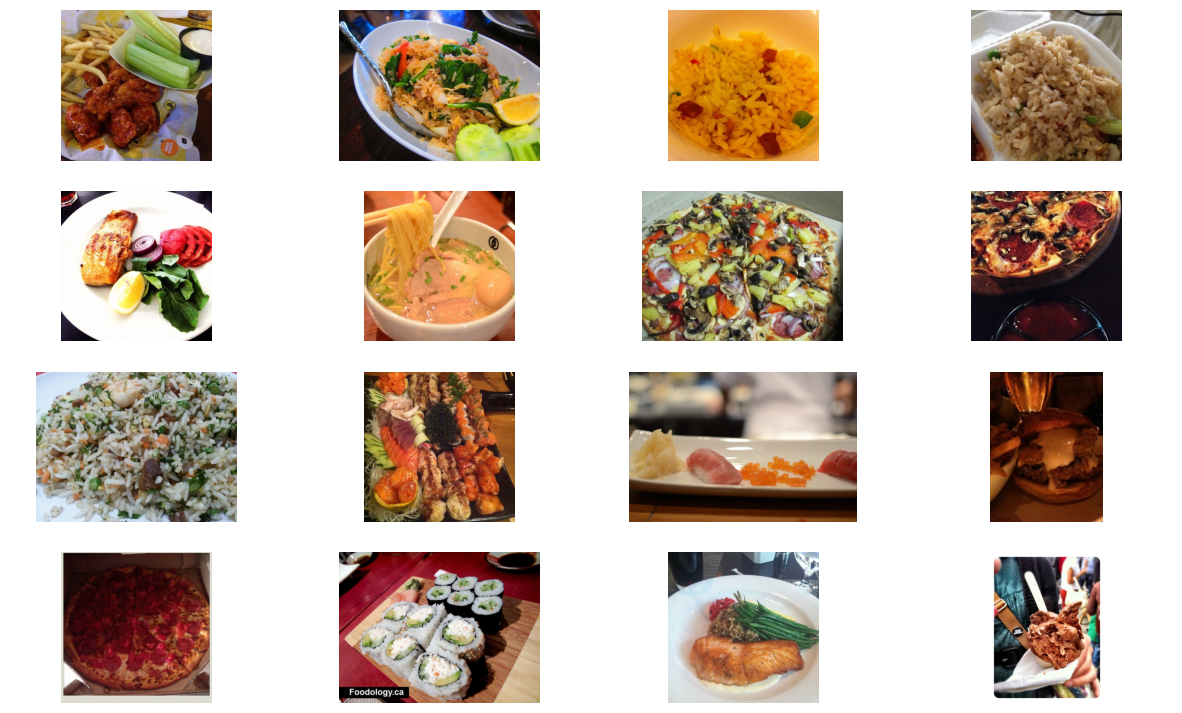

In [ ]:
import random
from PIL import Image

images = []
for folder in os.listdir(train_dir):
  for image in os.listdir(train_dir + '/' + folder):
    images.append(os.path.join(train_dir, folder, image))

plt.figure(1, figsize=(15, 9))
plt.axis('off')
n = 0
for i in range(16):
  n += 1
  random_img = random.choice(images)
  imgs = mpimg.imread(random_img)
  plt.subplot(4, 4, n)
  plt.axis('off')
  plt.imshow(imgs)

In [ ]:
resnet_url = "https://www.kaggle.com/models/google/resnet-v2/TensorFlow2/50-feature-vector/2"
efficientrel_url = "https://www.kaggle.com/models/tensorflow/efficientnet/TensorFlow2/b0-feature-vector/1"

In [ ]:
import tensorflow as tf
import tensorflow_hub as hub

In [ ]:
IMAGE_SHAPE = (224, 224)

In [ ]:
def create_model(model_url, num_classes = 10):
  feature_extractor_layer = hub.KerasLayer(model_url,
                                           trainable = False,
                                           name = 'Feature_extraction_layer',
                                           input_shape = IMAGE_SHAPE + (3, ))
  inputs = tf.keras.layers.Input(shape=(224,224,3))
  x=tf.keras.layers.Lambda(lambda x: feature_extractor_layer(x))(inputs)
  outputs = tf.keras.layers.Dense(num_classes,activation='softmax',name = 'output_layer')(x)
  model=tf.keras.Model(inputs,outputs)
  return model

In [ ]:
resnet_model = create_model(resnet_url,
                            num_classes = train_data_10_percent.num_classes)

In [ ]:
train_data_10_percent.num_classes

10

In [ ]:
train_data_10_percent.num_classes

10

In [ ]:
resnet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,490 (80.04 KB)

 Trainable params: 20,490 (80.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
resnet_model.weights

[<Variable path=output_layer/kernel, shape=(2048, 10), dtype=float32, value=[[-0.02000542  0.02117693  0.03016325 ...  0.04154775 -0.03049058
   -0.05235368]
  [ 0.00118631  0.02301693 -0.01379579 ... -0.0240929  -0.03815769
   -0.0299019 ]
  [ 0.03776625 -0.04198463 -0.04799733 ...  0.04622654 -0.04787694
   -0.01492982]
  ...
  [-0.01006121 -0.02371571 -0.02104671 ...  0.0145191  -0.00616235
    0.05287342]
  [-0.03775265  0.00628259  0.0056062  ...  0.02003581  0.05294593
    0.0508387 ]
  [ 0.04742257 -0.02335763 -0.04951788 ... -0.04784076 -0.04447933
   -0.02737683]]>,
 <Variable path=output_layer/bias, shape=(10,), dtype=float32, value=[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]>]

In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
resnet_model.compile(loss='categorical_crossentropy',
                     optimizer=optimizer,
                     metrics=['accuracy'])

In [ ]:
resnet_history = resnet_model.fit(train_data_10_percent,
                 batch_size=32,
                 epochs=5,
                 steps_per_epoch=len(train_data_10_percent),
                 validation_data=(test_data_10_percent),
                 validation_steps=len(test_data_10_percent))

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 488s 21s/step - accuracy: 0.2192 - loss: 2.3983 - val_accuracy: 0.6032 - val_loss: 1.2428
Epoch 2/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 460s 20s/step - accuracy: 0.7196 - loss: 1.0054 - val_accuracy: 0.7244 - val_loss: 0.8491
Epoch 3/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 454s 20s/step - accuracy: 0.8193 - loss: 0.6377 - val_accuracy: 0.7424 - val_loss: 0.7818
Epoch 4/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 503s 20s/step - accuracy: 0.8830 - loss: 0.4659 - val_accuracy: 0.7724 - val_loss: 0.7019
Epoch 5/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 457s 20s/step - accuracy: 0.9139 - loss: 0.3904 - val_accuracy: 0.7704 - val_loss: 0.6836


In [ ]:
resnet_model.evaluate(test_data_10_percent)

79/79 ━━━━━━━━━━━━━━━━━━━━ 351s 4s/step - accuracy: 0.7704 - loss: 0.6908


[0.6836064457893372, 0.7703999876976013]

In [ ]:
resnet_model.layers

[<InputLayer name=input_layer_1, built=True>,
 <Lambda name=lambda_1, built=True>,
 <Dense name=output_layer, built=True>]

In [ ]:
resnet_model.layers[0]

<InputLayer name=input_layer_1, built=True>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def plot_loss_curve(history):
  loss=history.history['loss']
  val_loss=history.history['loss']
  accuracy=history.history['accuracy']
  val_accuracy=history.history['val_accuracy']
  epochs=range(len(history.history['loss']))
  #plot loss
  plt.plot(epochs,loss,label='training_loss')
  plt.plot(epochs,val_loss,label='Val_loss')
  plt.title('loss')
  plt.xlabel('Epochs')
  plt.legend()
  plt.figure()

  #plot accuracy
  plt.figure()
  plt.plot(epochs,accuracy,label='training_accuracy')
  plt.plot(epochs,val_accuracy,label='Val_accuracy')
  plt.title('accuracy')
  plt.xlabel('Epochs')
  plt.legend()

In [ ]:
efficientrel_model = create_model(efficientrel_url,
                                  train_data_10_percent.num_classes)

In [ ]:
optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3)
efficientrel_model.compile(loss='categorical_crossentropy',
                           optimizer=optimizer,
                           metrics='accuracy')

In [ ]:
efficientrel_history = efficientrel_model.fit(train_data_10_percent,
                       epochs=5,
                       steps_per_epoch=len(train_data_10_percent),
                       validation_data=test_data_10_percent,
                       validation_steps=len(test_data_10_percent))

In [ ]:
plot_loss_curve(efficientrel_history)

In [ ]:
efficientrel_model.evaluate(test_data_10_percent)

# 100% Data

In [ ]:
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_all_data.zip

import zipfile
zip_ref = zipfile.ZipFile('10_food_classes_all_data.zip', 'r')
zip_ref.extractall()
zip_ref.close()

import os

for dirpath, dirnames, filenames in os.walk('10_food_classes_all_data'):
  print(f'There are {len(dirnames)} directories and {len(filenames)} images in {dirpath}.')

--2026-01-26 07:34:45--  https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_all_data.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 173.194.202.207, 173.194.203.207, 74.125.199.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|173.194.202.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 519183241 (495M) [application/zip]
Saving to: ‘10_food_classes_all_data.zip.1’

10_food_classes_all 100%[===================>] 495.13M  82.0MB/s    in 7.4s    

2026-01-26 07:34:52 (67.1 MB/s) - ‘10_food_classes_all_data.zip.1’ saved [519183241/519183241]



In [ ]:
train_dir = '/content/10_food_classes_all_data/train'
test_dir = '/content/10_food_classes_all_data/test'

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
train_data_full = train_datagen.flow_from_directory(directory=train_dir,
                                                    target_size=(224, 224),
                                                    batch_size=32,)
test_data_full = test_datagen.flow_from_directory(directory=test_dir,
                                                    target_size=(224, 224),
                                                    batch_size=32,)

In [ ]:
optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3)
efficientrel_model.compile(loss='categorical_crossentropy',
                           optimizer=optimizer,
                           metrics='accuracy')

In [ ]:
efficientrel_history = efficientrel_model.fit(train_data_full,
                                              epochs=5,
                                              steps_per_epoch=len(train_data_full),
                                              validation_data=test_data_full,
                                              validation_steps=len(test_data_full))

In [ ]:
plot_loss_curve(efficientrel_history)

In [ ]:
efficientrel_model.evaluate(test_data_full)

In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
resnet_model.compile(loss='categorical_crossentropy',
                     optimizer=optimizer,
                     metrics='accuracy')

In [ ]:
resnet_history = resnet_model.fit(train_data_full,
                                  epochs = 5,
                                  steps_per_epoch=len(train_data_full),
                                  validation_data = test_data_full,
                                  validation_steps = len(test_data_full))

In [ ]:
plot_loss_curve(resnet_history)

In [ ]:
resnet_model.evaluate(test_data_full)